# Step 2: Exploratory Data Analysis (Superstore Sales Forecasting)

This notebook explores the cleaned Superstore sales dataset (2015–2018) to uncover:
- Overall sales trends and growth patterns
- Yearly seasonality (peak shopping periods vs. post-holiday troughs)
- Category and regional breakdowns
- Autocorrelation patterns to inform lag and rolling window feature engineering

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Set plotting styles
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (11, 4.5)

# Add project root to sys.path
project_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data_loader import load_clean
from src.features import monthly_sales

## 1. Load Cleaned Dataset
We use `load_clean()` from `src.data_loader` to load the preprocessed transactional records.

In [2]:
df = load_clean()
min_d = df['Order_Date'].min().strftime('%Y-%m-%d')
max_d = df['Order_Date'].max().strftime('%Y-%m-%d')
print(f'Total transactions: {len(df):,}')
print(f'Date span: {min_d} to {max_d}')
print(f'Total revenue: ${df["Sales"].sum():,.2f}')
df.head(3)

Total transactions: 9,800
Date span: 2015-01-03 to 2018-12-30
Total revenue: $2,261,536.78


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales
0,7981,CA-2015-103800,2015-01-03,2015-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,Texas,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2 X 4 Forms/...",16.448
1,742,CA-2015-112326,2015-01-04,2015-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540
2,741,CA-2015-112326,2015-01-04,2015-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,Illinois,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736


## 2. Monthly Resampling
For monthly demand planning and forecasting, transactions are aggregated to month-start (`MS`) intervals.

In [3]:
monthly = monthly_sales(df)
print(f'Total months in series: {len(monthly)}')
print('Any missing months?', monthly.isna().any())
monthly.describe().to_frame().T

Total months in series: 48
Any missing months? False


,count,mean,std,min,25%,50%,75%,max
Sales,48.0,47115.34964,24978.687305,4519.892,29621.712625,39202.1265,64391.969125,117938.155


## 3. Visualizing Monthly Sales Trend
Let us inspect the trajectory of sales across 2015–2018.

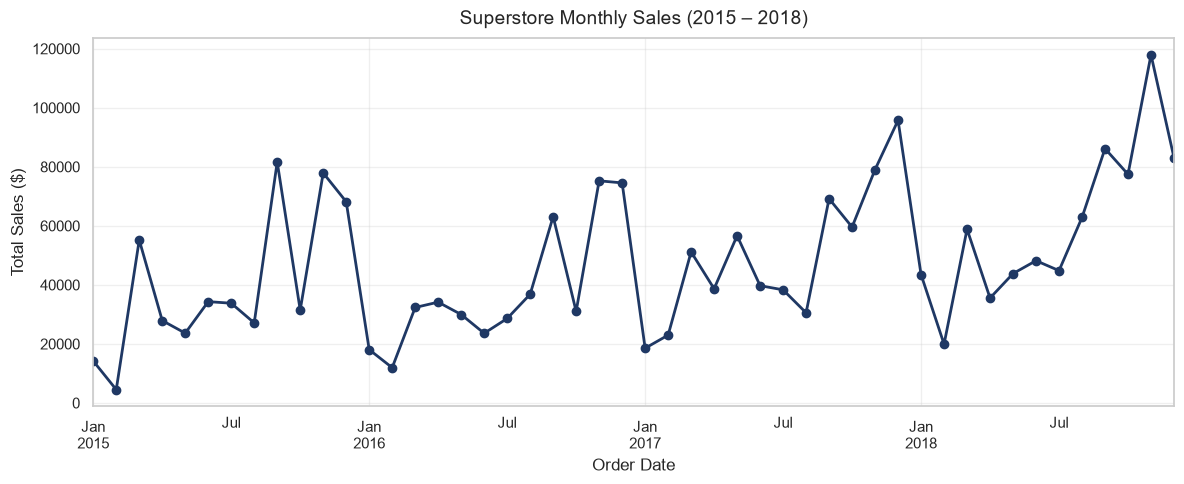

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
monthly.plot(ax=ax, marker='o', color='#1F3864', linewidth=2)
ax.set_title('Superstore Monthly Sales (2015 – 2018)', fontsize=14, pad=10)
ax.set_ylabel('Total Sales ($)', fontsize=12)
ax.set_xlabel('Order Date', fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Seasonality Analysis
Observing recurring spikes towards Q4 (November & December).

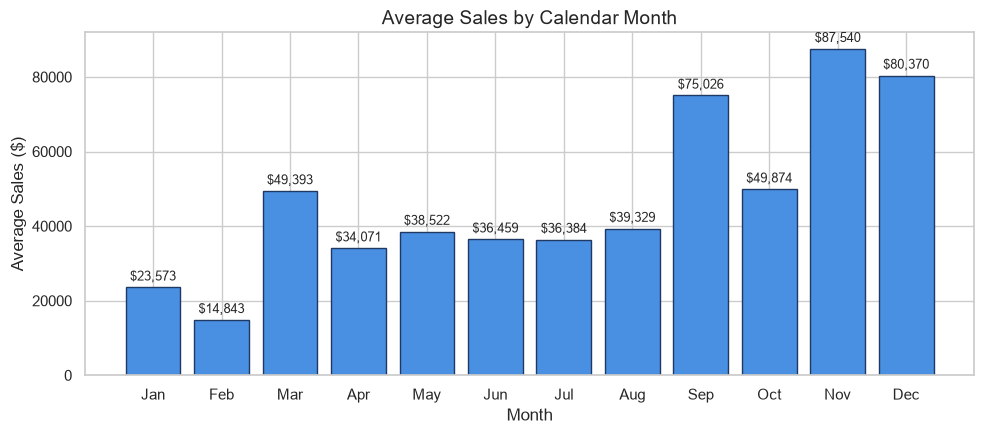

In [5]:
monthly_avg = monthly.groupby(monthly.index.month).mean()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(month_names, monthly_avg, color='#4A90E2', edgecolor='#1F3864')
ax.set_title('Average Sales by Calendar Month', fontsize=14)
ax.set_ylabel('Average Sales ($)', fontsize=12)
ax.set_xlabel('Month', fontsize=12)
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'${height:,.0f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords='offset points', ha='center', va='bottom', fontsize=9)
plt.tight_layout()
plt.show()

## 5. Sales Breakdown by Category & Region

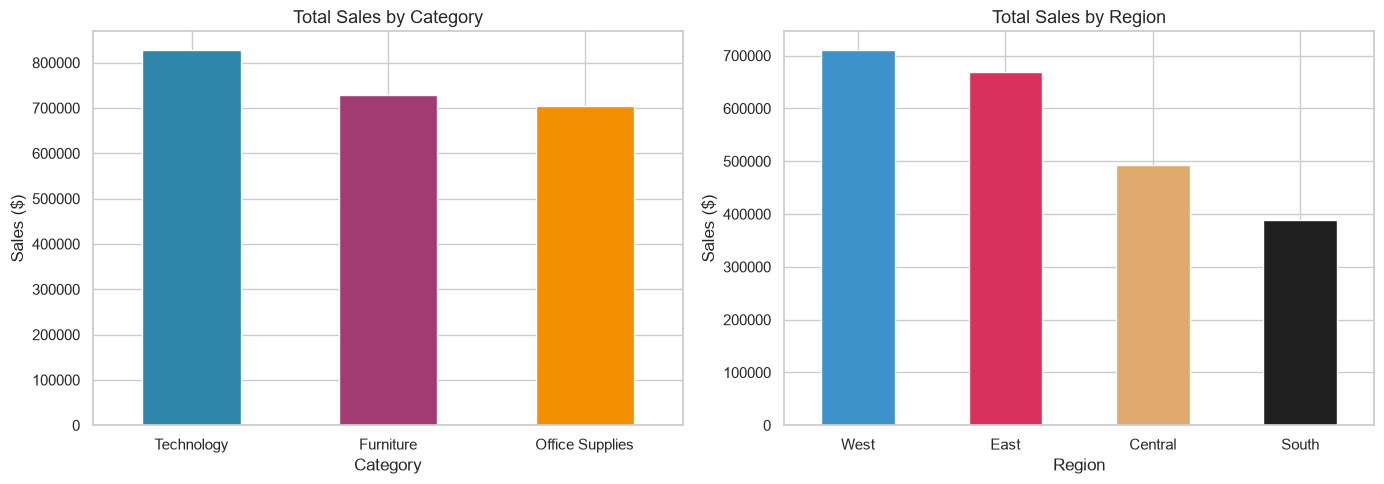

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Category Breakdown
cat_sales = df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
cat_sales.plot(kind='bar', ax=axes[0], color=['#2E86AB', '#A23B72', '#F18F01'], rot=0)
axes[0].set_title('Total Sales by Category', fontsize=13)
axes[0].set_ylabel('Sales ($)')

# Region Breakdown
reg_sales = df.groupby('Region')['Sales'].sum().sort_values(ascending=False)
reg_sales.plot(kind='bar', ax=axes[1], color=['#3E92CC', '#D8315B', '#E0A96D', '#202020'], rot=0)
axes[1].set_title('Total Sales by Region', fontsize=13)
axes[1].set_ylabel('Sales ($)')

plt.tight_layout()
plt.show()

## 6. Autocorrelation & Lag Features
Evaluating the correlation with previous months to motivate our lag choices in `src/features.py`.

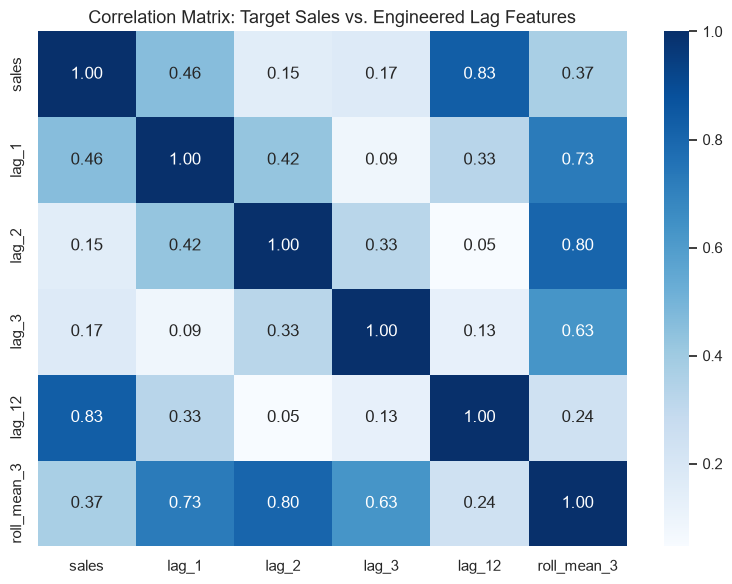

In [7]:
from src.features import build_features
feature_df = build_features(monthly)

fig, ax = plt.subplots(figsize=(8, 6))
corr = feature_df[['sales', 'lag_1', 'lag_2', 'lag_3', 'lag_12', 'roll_mean_3']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='Blues', ax=ax, cbar=True)
ax.set_title('Correlation Matrix: Target Sales vs. Engineered Lag Features', fontsize=13)
plt.tight_layout()
plt.show()

## 7. Key Findings & Next Steps

### Data Analysis Key Findings
- **Seasonal Dominance**: Strongest sales occur in November and December (~$75,000–$85,000 average), while January and February exhibit a marked post-holiday slowdown (~$15,000–$20,000 average).
- **Lag 12 Significance**: `lag_12` (sales 1 year ago) has high predictive power due to yearly cyclicality.
- **Trend**: Overall yearly sales show positive year-over-year expansion from 2015 through 2018.

### Next Steps
- Use `src/baseline.py` to establish naive and seasonal benchmark scores.
- Train Ridge, Random Forest, and XGBoost regressors via `src/train.py` using walk-forward validation.